# Adaptive Gaussian Killgen sampling and Julia AC-OPF verification

## 1. Imports, paths, dataset, and Julia verifier


In [17]:
import csv
import hashlib
import json
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from juliacall import Main as jl


In [18]:
DATASET_NAME = "alabama"
TIME_SLICE = "16h"
DATA_DIR = Path("../power_grid/US/gridsfm_data") / TIME_SLICE
DATA_PATH = DATA_DIR / f"{DATASET_NAME}_model.json"
JULIA_SCRIPT = Path("../verifier/acopf_verifier.jl")
OUTPUT_DIR = Path("../results/gaussian_killgen") / DATASET_NAME
SCENARIO_PATH = OUTPUT_DIR / "acopf_labeled_scenarios.npz"
DATASET_LABEL = DATASET_NAME.replace("_", " ").title()

assert DATA_PATH.is_file(), f"Grid case not found: {DATA_PATH}"
assert JULIA_SCRIPT.is_file(), f"Julia verifier not found: {JULIA_SCRIPT}"
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
assert isinstance(data.get("bus"), dict), "Expected case with a 'bus' dictionary"
CASE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_LABEL, "| Case:", DATA_PATH)
print("Julia verifier:", JULIA_SCRIPT)
print("Output directory:", OUTPUT_DIR)
print("Buses:", len(data["bus"]), "| baseMVA:", data.get("baseMVA"))

Dataset: Alabama | Case: ../power_grid/US/gridsfm_data/16h/alabama_model.json
Julia verifier: ../verifier/acopf_verifier.jl
Output directory: ../results/gaussian_killgen/alabama
Buses: 494 | baseMVA: 100.0


## 2. Preserve generator IDs and build the Gaussian feature space

In [19]:
active_gen_ids = [str(gid) for gid, g in data["gen"].items()
                  if int(g.get("gen_status", g.get("status", 1))) == 1]
gen_ids = []
for gid in active_gen_ids:
    g = data["gen"][gid]
    try:
        pmax, qmax = float(g.get("pmax", np.nan)), float(g.get("qmax", np.nan))
    except (TypeError, ValueError):
        continue
    if np.isfinite(pmax) and np.isfinite(qmax) and pmax > 0.01:
        gen_ids.append(gid)

gens = np.asarray([[float(data["gen"][gid]["pmax"]),
                    float(data["gen"][gid]["qmax"])] for gid in gen_ids], dtype=float)
n_gens = len(gen_ids)
if n_gens < 1 or len(active_gen_ids) < 3:
    raise ValueError("KILLGEN requires at least 3 active generators and 1 eligible generator")

gen_index = {gid: i for i, gid in enumerate(gen_ids)}
feature_std = np.maximum(gens.std(axis=0, ddof=0), 1e-8)
print(f"Active generators: {len(active_gen_ids)} | eligible: {n_gens}")
print("Gaussian selection features [Pmax,Qmax] shape:", gens.shape)
print("Feature means:", gens.mean(axis=0))


Active generators: 55 | eligible: 55
Gaussian selection features [Pmax,Qmax] shape: (55, 2)
Feature means: [2.30908668 1.25738201]


## 3. Initialize the existing PowerModels AC-OPF verifier for this case


In [20]:
jl.include(str(JULIA_SCRIPT.resolve()))
summary_text = jl.ACOPFVerifier.initialize_case(str(DATA_PATH.resolve()))
print("Julia case initialized:\n", json.loads(str(summary_text)))


Julia case initialized:
 {'n_buses': 494, 'baseMVA': 100.0, 'supported_modes': ['branch', 'bus', 'gen', 'load'], 'initialized': True, 'n_loads': 494, 'n_generators': 55, 'n_branches': 864, 'per_unit': True}


In [21]:
def verify_scenario(patch):
    start = time.perf_counter()
    try:
        if not isinstance(patch, dict) or not patch:
            raise ValueError("patch must be a nonempty dictionary")
        raw = jl.ACOPFVerifier.verify_scenario_json(
            json.dumps(patch, allow_nan=False)
        )
        result = json.loads(str(raw))
        result["elapsed_s"] = time.perf_counter() - start
        return result
    except Exception as exc:
        return {
            "accepted": False, "status": "CALL_ERROR", "objective": None,
            "reason": str(exc)[:1000], "termination_status": "ERROR",
            "primal_status": "UNKNOWN", "elapsed_s": time.perf_counter() - start,
        }

def build_killgen_patch(selected_ids):
    if not selected_ids:
        raise ValueError("A KILLGEN scenario must turn off at least one generator")
    if len(set(selected_ids)) != len(selected_ids):
        raise ValueError("Duplicate generator ID in one scenario")
    if any(gid not in gen_index for gid in selected_ids):
        raise ValueError("Unknown/ineligible generator ID")
    return {"gen": {str(gid): {"gen_status": 0} for gid in selected_ids}}

In [22]:
print(f"Verifying the original {DATASET_LABEL} case")
baseline_patch = {"gen": {active_gen_ids[0]: {"gen_status": 1}}}
baseline_result = verify_scenario(baseline_patch)
print("Baseline:\n", baseline_result)
if not baseline_result["accepted"]:
    raise RuntimeError("Baseline not confirmed: " + str(baseline_result))

Verifying the original Alabama case
Baseline:
 {'stage': 'opf', 'modes': ['gen'], 'termination_status': 'LOCALLY_SOLVED', 'objective': 198538.08988997107, 'primal_status': 'FEASIBLE_POINT', 'reason': '', 'warnings': [], 'applied_components': {'gen': 1}, 'solve_time': 0.6457030773162842, 'accepted': True, 'status': 'OPF_SOLVED', 'elapsed_s': 1.21943833300611}


## 4. Gaussian initialization, initial scale, and outage probabilities


In [23]:
SEED = 42
iterations = 10
samples_per_iteration = 2
alpha = 0.30

KILL_COUNTS = np.array([1, 2, 3], dtype=int)
KILL_PROBABILITIES = np.array([0.70, 0.20, 0.10], dtype=float)
INITIAL_SCALE_MIN= 1.0
INITIAL_SCALE_MAX= 1.8
COV_REG = 1e-8

assert 0 < alpha <= 1 and iterations >= 1 and samples_per_iteration >= 1
assert np.isclose(KILL_PROBABILITIES.sum(), 1) and (KILL_PROBABILITIES >= 0).all()
assert 0 < INITIAL_SCALE_MIN <= INITIAL_SCALE_MAX

# Only choose outage counts that leave at least TWO of all active generators online.
MAX_KILLED = min(3, n_gens, len(active_gen_ids) - 2)
allowed = KILL_COUNTS <= MAX_KILLED
kill_counts = KILL_COUNTS[allowed]
kill_probabilities = KILL_PROBABILITIES[allowed]
kill_probabilities = kill_probabilities / kill_probabilities.sum()
assert len(kill_counts) >= 1

scale_rng = np.random.default_rng(SEED + 1)
INITIAL_SCALE = float(scale_rng.uniform(INITIAL_SCALE_MIN, INITIAL_SCALE_MAX))
rng = np.random.default_rng(SEED)

initial_cov_base = np.cov(gens, rowvar=False, bias=True) if len(gens) >= 2 else np.zeros((2, 2))
initial_cov_base = np.atleast_2d(initial_cov_base).reshape(2, 2)
killgen_mu = gens.mean(axis=0).copy()
killgen_cov = INITIAL_SCALE**2 * (0.5 * (initial_cov_base + initial_cov_base.T)) + np.eye(2) * COV_REG
initial_mu, initial_cov = killgen_mu.copy(), killgen_cov.copy()

history, verification_log = [], []
explain_candidates, explain_labels, explain_metadata = [], [], []
selected_gen_ids_log, outage_count_log, target_log = [], [], []
last_targets = last_selected = last_selected_accepted = None
last_counts = None
print("Initial scale:", INITIAL_SCALE, "| outage probability:", dict(zip(kill_counts, kill_probabilities)))
print("Initial Gaussian mean [Pmax,Qmax]:", killgen_mu)
print("Initial Gaussian std:", np.sqrt(np.diag(killgen_cov)))
print("Initial Gaussian covariance:\n", killgen_cov)


Initial scale: 1.5218394101607287 | outage probability: {np.int64(1): np.float64(0.7000000000000001), np.int64(2): np.float64(0.20000000000000004), np.int64(3): np.float64(0.10000000000000002)}
Initial Gaussian mean [Pmax,Qmax]: [2.30908668 1.25738201]
Initial Gaussian std: [5.0775203  2.37762439]
Initial Gaussian covariance:
 [[25.78121241 11.51083647]
 [11.51083647  5.65309772]]


## 5. Sample Gaussian targets, select nearest real generators, and turn them OFF


In [24]:
def sample_killgen(rng, mu, cov, n_scenarios):
    targets = rng.multivariate_normal(mu, cov, size=(n_scenarios, MAX_KILLED), check_valid="raise")
    n_off = rng.choice(kill_counts, size=n_scenarios, p=kill_probabilities).astype(int)
    candidates = np.ones((n_scenarios, n_gens), dtype=np.int8)
    selected_ids = np.full((n_scenarios, MAX_KILLED), "", dtype="<U64")
    selected_values = np.full((n_scenarios, MAX_KILLED, 2), np.nan, dtype=float)
    for s in range(n_scenarios):
        chosen = []
        for target in targets[s, :n_off[s]]:
            dists = np.sum(((gens - target) / feature_std) ** 2, axis=1)
            dists[chosen] = np.inf
            ix = int(np.argmin(dists))
            chosen.append(ix)
        candidates[s, chosen] = 0
        selected_ids[s, :n_off[s]] = [gen_ids[ix] for ix in chosen]
        selected_values[s, :n_off[s]] = gens[chosen]
    assert np.array_equal((candidates == 0).sum(axis=1), n_off)
    assert np.all(len(active_gen_ids) - n_off >= 2)
    return candidates, selected_ids, selected_values, targets, n_off


## 6. Adaptive Gaussian loop with Julia acceptance and per-iteration checkpoints


In [25]:
for iteration in range(iterations):
    candidates, selected_ids, selected_features, targets, outage_counts = sample_killgen(
        rng, killgen_mu, killgen_cov, samples_per_iteration)
    good_selected_features = []
    selected_all = []
    selected_accepted = []
    for j in range(samples_per_iteration):
        ids = selected_ids[j, :outage_counts[j]].tolist()
        verification = verify_scenario(build_killgen_patch(ids))
        accepted = bool(verification.get("accepted", False))
        row = dict(iteration=iteration+1, scenario=j+1,
                   n_gens_killed=int(outage_counts[j]), selected_generator_ids=",".join(ids),
                   **verification)
        verification_log.append(row)
        explain_candidates.append(candidates[j].copy())
        explain_labels.append(int(accepted))
        explain_metadata.append((iteration+1, j+1, str(verification.get("status", "UNKNOWN")),
                                 str(verification.get("termination_status", "UNKNOWN")),
                                 str(verification.get("primal_status", "UNKNOWN"))))
        selected_gen_ids_log.append(selected_ids[j].copy())
        outage_count_log.append(int(outage_counts[j]))
        target_log.append(targets[j].copy())
        selected_all.append(selected_features[j, :outage_counts[j]].copy())
        if accepted:
            good_selected_features.append(selected_features[j, :outage_counts[j]].copy())
            selected_accepted.append(selected_features[j, :outage_counts[j]].copy())
        print(f"Iteration {iteration+1}/{iterations}, scenario {j+1}/{samples_per_iteration}: "
              f"killed {ids}; Julia {verification.get('status')} "
              f"({verification.get('termination_status')})", flush=True)
        if verification.get("reason"):
            print("  Reason:", str(verification["reason"])[:250], flush=True)

    n_accepted = len(good_selected_features)
    if n_accepted:
        flattened = np.concatenate(good_selected_features, axis=0)
        empirical_mu = flattened.mean(axis=0)
        empirical_cov = (np.cov(flattened, rowvar=False, bias=True) if len(flattened) >= 2
                         else killgen_cov.copy())
        killgen_mu = (1-alpha)*killgen_mu + alpha*empirical_mu
        killgen_cov = (1-alpha)*killgen_cov + alpha*empirical_cov
        killgen_cov = 0.5*(killgen_cov+killgen_cov.T) + np.eye(2)*COV_REG

    history.append(dict(iteration=iteration+1, accepted_count=n_accepted,
                        rejected_count=samples_per_iteration-n_accepted,
                        acceptance_rate=n_accepted/samples_per_iteration,
                        mean_outages=float(np.mean(outage_counts)),
                        selected_generator_count=int(outage_counts.sum()),
                        gaussian_mu=killgen_mu.copy(), gaussian_std=np.sqrt(np.diag(killgen_cov)),
                        gaussian_cov=killgen_cov.copy(), updated=bool(n_accepted)))
    last_targets = targets.copy()
    last_selected = np.concatenate(selected_all, axis=0)
    last_selected_accepted = (np.concatenate(selected_accepted, axis=0)
                              if selected_accepted else np.empty((0,2)))
    last_counts = outage_counts.copy()

    # A compatible archive for the separate pretrained-model SHAP notebook.
    # "candidates" contains generator on/off values (1=on, 0=off) in gen_ids order.
    np.savez_compressed(
        SCENARIO_PATH,
        candidates=np.stack(explain_candidates).astype(np.int8),
        accepted=np.asarray(explain_labels, dtype=np.int8),
        gen_ids=np.asarray(gen_ids, dtype=str),
        gen_features=gens.astype(np.float32),
        active_gen_ids=np.asarray(active_gen_ids, dtype=str),
        selected_gen_ids=np.stack(selected_gen_ids_log).astype(str),
        n_killed=np.asarray(outage_count_log, dtype=np.int16),
        gaussian_targets=np.stack(target_log).astype(np.float32),
        iteration=np.asarray([t[0] for t in explain_metadata], dtype=np.int64),
        scenario=np.asarray([t[1] for t in explain_metadata], dtype=np.int64),
        status=np.asarray([t[2] for t in explain_metadata], dtype=str),
        termination_status=np.asarray([t[3] for t in explain_metadata], dtype=str),
        primal_status=np.asarray([t[4] for t in explain_metadata], dtype=str),
        dataset_name=np.asarray(DATASET_NAME),
        source_case_sha256=np.asarray(CASE_SHA256),
        source_case_path=np.asarray(str(DATA_PATH.resolve())),
        initial_scale=np.asarray(INITIAL_SCALE),
        initial_gaussian_mu=initial_mu.astype(np.float64),
        initial_gaussian_cov=initial_cov.astype(np.float64),
        gaussian_mu=killgen_mu.astype(np.float64),
        gaussian_cov=killgen_cov.astype(np.float64),
    )
    print(f"Completed iteration {iteration+1}: accepted {n_accepted}/{samples_per_iteration} "
          f"| mu={np.round(killgen_mu,4)} std={np.round(np.sqrt(np.diag(killgen_cov)),4)}")

print("Total Julia accepted:", int(sum(h["accepted_count"] for h in history)),
      "/", iterations*samples_per_iteration)
print("Saved scenarios:", SCENARIO_PATH)


Iteration 1/10, scenario 1/2: killed ['58']; Julia OPF_SOLVED (LOCALLY_SOLVED)
Iteration 1/10, scenario 2/2: killed ['21', '54']; Julia OPF_SOLVED (LOCALLY_SOLVED)
Completed iteration 1: accepted 2/2 | mu=[2.0729 1.1314] std=[4.2514 1.9978]
Iteration 2/10, scenario 1/2: killed ['40']; Julia OPF_SOLVED (LOCALLY_SOLVED)
Iteration 2/10, scenario 2/2: killed ['44']; Julia OPF_SOLVED (LOCALLY_SOLVED)
Completed iteration 2: accepted 2/2 | mu=[1.8005 1.0089] std=[3.612  1.7161]
Iteration 3/10, scenario 1/2: killed ['28']; Julia OPF_SOLVED (LOCALLY_SOLVED)
Iteration 3/10, scenario 2/2: killed ['49', '21']; Julia OPF_SOLVED (LOCALLY_SOLVED)
Completed iteration 3: accepted 2/2 | mu=[1.5132 0.8737] std=[3.0407 1.4492]
Iteration 4/10, scenario 1/2: killed ['18', '7']; Julia OPF_SOLVED (LOCALLY_SOLVED)
Iteration 4/10, scenario 2/2: killed ['40', '16']; Julia OPF_SOLVED (LOCALLY_SOLVED)
Completed iteration 4: accepted 2/2 | mu=[1.6401 0.9718] std=[2.7624 1.3836]
Iteration 5/10, scenario 1/2: killed 

## 7. Plots — Julia acceptance, Gaussian mean/std, and generator outages

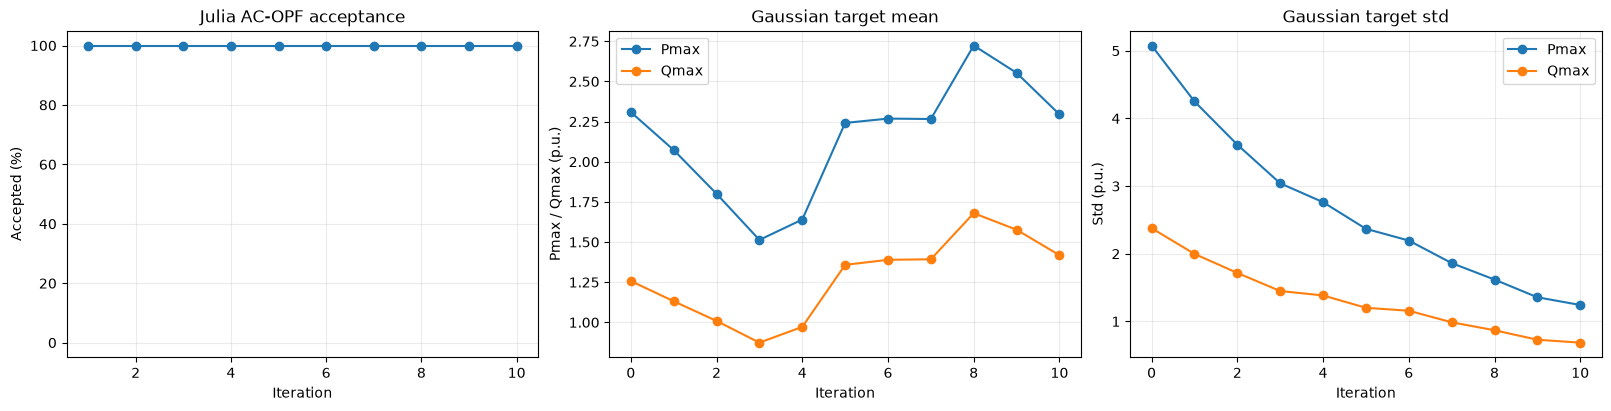

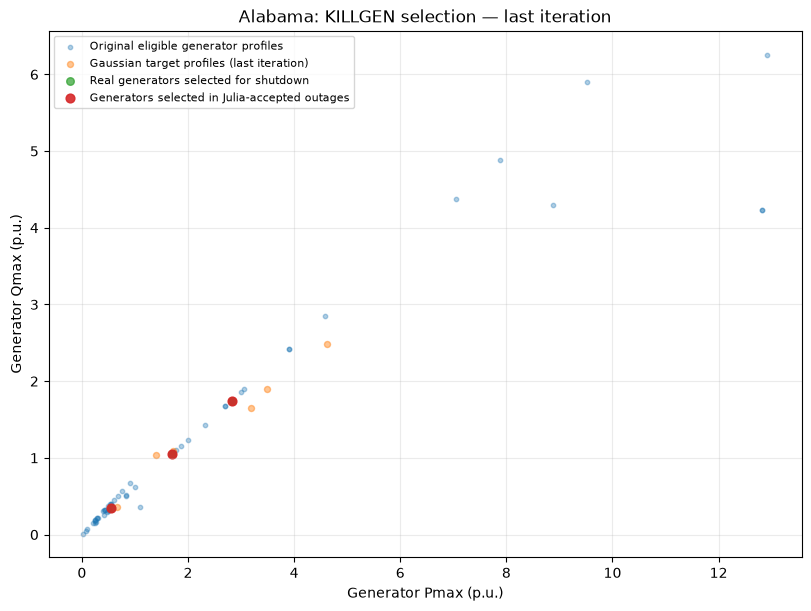

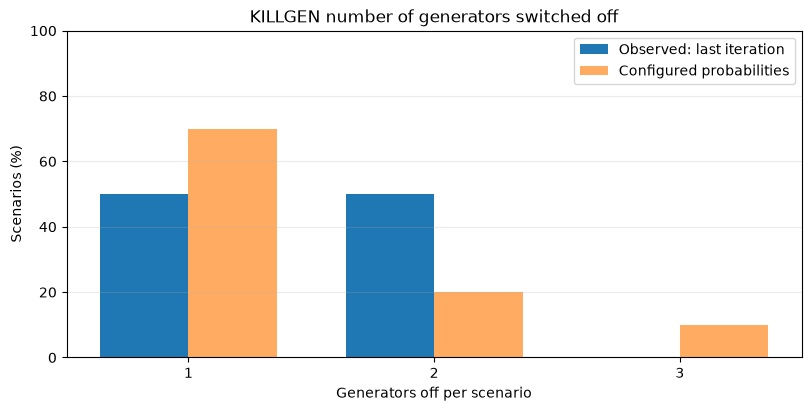

In [26]:
xs = [h["iteration"] for h in history]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(xs, [100*h["acceptance_rate"] for h in history], marker="o")
axes[0].set(title="Julia AC-OPF acceptance", xlabel="Iteration", ylabel="Accepted (%)", ylim=(-5,105))
for j, label in enumerate(("Pmax", "Qmax")):
    axes[1].plot([0]+xs, [initial_mu[j]]+[h["gaussian_mu"][j] for h in history],
                 marker="o", label=label)
    axes[2].plot([0]+xs, [np.sqrt(initial_cov[j,j])]+[h["gaussian_std"][j] for h in history],
                 marker="o", label=label)
axes[1].set(title="Gaussian target mean", xlabel="Iteration", ylabel="Pmax / Qmax (p.u.)")
axes[2].set(title="Gaussian target std", xlabel="Iteration", ylabel="Std (p.u.)")
axes[1].legend(); axes[2].legend()
for ax in axes: ax.grid(alpha=0.25)
fig.savefig(OUTPUT_DIR/"sampling_acceptance_and_noise.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8,6), constrained_layout=True)
vrng = np.random.default_rng(SEED+2)
for arr, name, size, alpha_plot in [
    (gens,"Original eligible generator profiles",10,.35),
    (last_targets.reshape(-1,2),"Gaussian target profiles (last iteration)",19,.45),
    (last_selected,"Real generators selected for shutdown",30,.7),
    (last_selected_accepted,"Generators selected in Julia-accepted outages",40,.9),
]:
    if len(arr):
        points=arr[vrng.choice(len(arr),size=min(3000,len(arr)),replace=False)]
        ax.scatter(points[:,0],points[:,1],label=name,s=size,alpha=alpha_plot,rasterized=True)
ax.set(title=f"{DATASET_LABEL}: KILLGEN selection — last iteration",xlabel="Generator Pmax (p.u.)",ylabel="Generator Qmax (p.u.)")
ax.grid(alpha=.25);ax.legend(fontsize=8)
fig.savefig(OUTPUT_DIR/"generator_gaussian_target_and_selected.png", dpi=180, bbox_inches="tight")
plt.show()

obs=np.asarray([(last_counts==k).mean()*100 for k in kill_counts])
fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
xx=np.arange(len(kill_counts))
ax.bar(xx-.18,obs,width=.36,label="Observed: last iteration")
ax.bar(xx+.18,kill_probabilities*100,width=.36,alpha=.65,label="Configured probabilities")
ax.set_xticks(xx,[str(k) for k in kill_counts]); ax.set(
    title="KILLGEN number of generators switched off",xlabel="Generators off per scenario",ylabel="Scenarios (%)")
ax.set_ylim(0, max(100,float(obs.max())+5));ax.grid(axis="y",alpha=.25);ax.legend()
fig.savefig(OUTPUT_DIR/"generator_outage_count_distribution.png",dpi=180,bbox_inches="tight")
plt.show()


## 8. Export verifier outcomes and Gaussian history CSVs


In [27]:
def write_csv(path, rows, fields):
    with path.open("w", newline="", encoding="utf-8") as f:
        writer=csv.DictWriter(f,fieldnames=fields,extrasaction="ignore")
        writer.writeheader();writer.writerows(rows)

log_fields=["iteration","scenario","accepted","status","termination_status",
            "primal_status","objective","solve_time","elapsed_s","reason",
            "n_gens_killed","selected_generator_ids"]
write_csv(OUTPUT_DIR/"verification_log.csv",verification_log,log_fields)
history_rows=[]
for h in history:
    history_rows.append(dict(iteration=h["iteration"],accepted_count=h["accepted_count"],
        rejected_count=h["rejected_count"],acceptance_rate=h["acceptance_rate"],
        mean_outages=h["mean_outages"],selected_generator_count=h["selected_generator_count"],
        updated=h["updated"], pmax_mu=h["gaussian_mu"][0],qmax_mu=h["gaussian_mu"][1],
        pmax_std=h["gaussian_std"][0],qmax_std=h["gaussian_std"][1],
        pmax_qmax_cov=h["gaussian_cov"][0,1]))
write_csv(OUTPUT_DIR/"sampling_history.csv",history_rows,list(history_rows[0]))
print("Saved candidate archive:",SCENARIO_PATH)
print("Saved logs and plots to:",OUTPUT_DIR)


Saved candidate archive: ../results/gaussian_killgen/alabama/acopf_labeled_scenarios.npz
Saved logs and plots to: ../results/gaussian_killgen/alabama
